# 01 · Données LYCOS-IDS2017 : exploration et qualité

**Date :** 21 octobre 2026 (code simplifié le 3 novembre 2026)

**Ce qui est fait :**
1. Chargement des 5 jours étiquetés (`data/raw/lycos_labelled/`) avec les bons types (`timestamp` en float64, caractéristiques en float32).
2. Contrôle qualité par jour : flux, valeurs manquantes, infinies, doublons.
3. Répartition des classes par jour et rôle de chaque jour dans le découpage.
4. Unité et plage de `timestamp`, chronologie des attaques.
5. Où tombent les attaques avec un découpage 80/20.
6. Caractéristiques constantes et IP sources des attaques.

**Pourquoi :** connaître les données avant la préparation (notebook 02), vérifier qu'aucune attaque du test n'apparaît dans train/val, et repérer les pièges (fuite par IP, colonnes inutiles).

Rien n'est écrit dans `data/processed/` ici ; seules les figures vont dans `reports/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

# Pour importer notre code qui est dans src/
sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import DAYS, ID_COLS, LABEL, BENIGN, TS, ROOT, feature_columns, load_day, read_header

REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Jours d'entraînement/validation et jours de test
train_days = ["lun", "mar", "mer"]
test_days = ["jeu", "ven"]


def to_local_time(timestamps):
    """Convertit des timestamps (µs, UTC) en heure locale du banc d'essai (Canada, UTC-3 en juillet)."""
    utc_time = pd.to_datetime(timestamps, unit="us", utc=True)
    return utc_time.dt.tz_convert("America/Halifax")

## 1. Colonnes

In [2]:
cols = read_header()
features = feature_columns(cols)
print(len(cols), "colonnes :", len(ID_COLS), "identifiants/cible et", len(features), "caractéristiques")
print("Identifiants (jamais caractéristiques) :", ID_COLS)
print("Caractéristiques :", features)

83 colonnes : 6 identifiants/cible et 77 caractéristiques
Identifiants (jamais caractéristiques) : ['flow_id', 'src_addr', 'src_port', 'dst_addr', 'timestamp', 'label']
Caractéristiques : ['dst_port', 'ip_prot', 'flow_duration', 'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std'

## 2. Qualité et classes, jour par jour

On charge un jour à la fois (RAM limitée). Pour la suite, on garde seulement 4 colonnes (`day`, `timestamp`, `label`, `src_addr`) et le minimum / maximum de chaque caractéristique.

In [3]:
quality_rows = []
kept_tables = []
min_per_day = {}
max_per_day = {}

for day in DAYS:
    df = load_day(day)
    x = df[features]

    quality_rows.append({
        "jour": day,
        "rôle": DAYS[day][1],
        "flux": len(df),
        "manquantes": df.isna().sum().sum(),
        "infinies": np.isinf(x.to_numpy()).sum(),
        "doublons": df.duplicated().sum(),
        "attaques": (df[LABEL] != BENIGN).sum(),
        "Mo en RAM": round(df.memory_usage(deep=True).sum() / 1e6),
    })
    min_per_day[day] = x.min()
    max_per_day[day] = x.max()
    kept_tables.append(df[["day", TS, LABEL, "src_addr"]])
    del df, x   # libère la mémoire avant le jour suivant

flows = pd.concat(kept_tables, ignore_index=True)
flows[LABEL] = flows[LABEL].astype(str)

quality = pd.DataFrame(quality_rows).set_index("jour")
quality.loc["total"] = quality.sum(numeric_only=True)
quality

,rôle,flux,manquantes,infinies,doublons,attaques,Mo en RAM
jour,,,,,,,
lun,train/val,367181.0,0.0,0.0,0.0,0.0,153.0
mar,train/val,319637.0,0.0,0.0,0.0,6962.0,133.0
mer,train/val,495237.0,0.0,0.0,0.0,176304.0,206.0
jeu,test,112481.0,0.0,0.0,0.0,2033.0,47.0
ven,test,542962.0,0.0,0.0,0.0,256524.0,225.0
total,NaN,1837498.0,0.0,0.0,0.0,441823.0,764.0


In [4]:
# Nombre de flux par classe (lignes) et par jour (colonnes)
classes = pd.crosstab(flows[LABEL], flows["day"])
classes = classes[list(DAYS)]   # remet les jours dans l'ordre lun -> ven
classes["total"] = classes.sum(axis=1)
classes = classes.sort_values("total", ascending=False)
classes

day,lun,mar,mer,jeu,ven,total
label,,,,,,
benign,367181,312675,318933,110448,286438,1395675
portscan,0,0,0,0,160106,160106
dos_hulk,0,0,158988,0,0,158988
ddos,0,0,0,0,95683,95683
dos_goldeneye,0,0,6765,0,0,6765
dos_slowloris,0,0,5674,0,0,5674
dos_slowhttptest,0,0,4866,0,0,4866
ftp_patator,0,4003,0,0,0,4003
ssh_patator,0,2959,0,0,0,2959


In [5]:
# Vérification clé : aucune attaque du test (jeu, ven) ne doit apparaître dans train/val (lun, mar, mer)
in_train_days = flows["day"].isin(train_days)
attacks_train = set(flows.loc[in_train_days, LABEL]) - {BENIGN}
attacks_test = set(flows.loc[~in_train_days, LABEL]) - {BENIGN}

print("Attaques en train/val :", sorted(attacks_train))
print("Attaques en test      :", sorted(attacks_test))
print("En commun             :", sorted(attacks_train & attacks_test))

Attaques en train/val : ['dos_goldeneye', 'dos_hulk', 'dos_slowhttptest', 'dos_slowloris', 'ftp_patator', 'heartbleed', 'ssh_patator']
Attaques en test      : ['bot', 'ddos', 'portscan', 'webattack_bruteforce', 'webattack_sql_injection', 'webattack_xss']
En commun             : []


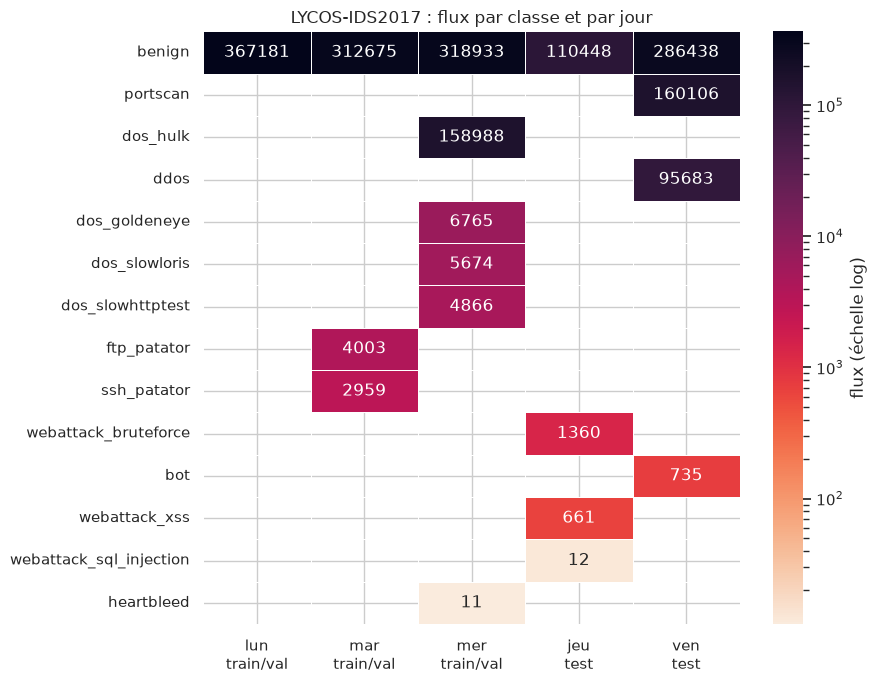

In [6]:
counts = classes.drop(columns="total")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(counts, mask=(counts == 0), annot=True, fmt="d", norm=LogNorm(), cmap="rocket_r",
            cbar_kws={"label": "flux (échelle log)"}, linewidths=0.5, ax=ax)
ax.set_xticklabels([day + "\n" + DAYS[day][1] for day in counts.columns], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("LYCOS-IDS2017 : flux par classe et par jour")
fig.tight_layout()
fig.savefig(REPORTS / "01_attaques_par_jour.png", dpi=150)
plt.show()

## 3. `timestamp` : unité et plage

Les valeurs ont 16 chiffres (environ 1,5·10¹⁵) : ce sont des **microsecondes** depuis 1970 (temps Unix). Elles restent exactes en float64 (exact jusqu'à 2⁵³ ≈ 9·10¹⁵).

In [7]:
span_rows = []
for day in DAYS:
    t = flows.loc[flows["day"] == day, TS]
    start = pd.to_datetime(t.min(), unit="us", utc=True)
    end = pd.to_datetime(t.max(), unit="us", utc=True)
    span_rows.append({
        "jour": day,
        "début (UTC)": start,
        "fin (UTC)": end,
        "durée": end - start,
        "flux": len(t),
        "déjà trié": t.is_monotonic_increasing,
        "valeurs entières": (t % 1 == 0).all(),
    })
pd.DataFrame(span_rows).set_index("jour")

,début (UTC),fin (UTC),durée,flux,déjà trié,valeurs entières
jour,,,,,,
lun,2017-07-03 11:56:37.567312+00:00,2017-07-03 20:01:34.164007+00:00,0 days 08:04:56.596695,367181,True,True
mar,2017-07-04 11:53:44.398274+00:00,2017-07-04 20:00:30.041663+00:00,0 days 08:06:45.643389,319637,True,True
mer,2017-07-05 11:42:42.084372+00:00,2017-07-05 20:07:59.170242+00:00,0 days 08:25:17.085870,495237,True,True
jeu,2017-07-06 11:59:00.490140+00:00,2017-07-06 14:59:58.708313+00:00,0 days 03:00:58.218173,112481,True,True
ven,2017-07-07 11:59:50.315195+00:00,2017-07-07 20:02:39.567285+00:00,0 days 08:02:49.252090,542962,True,True


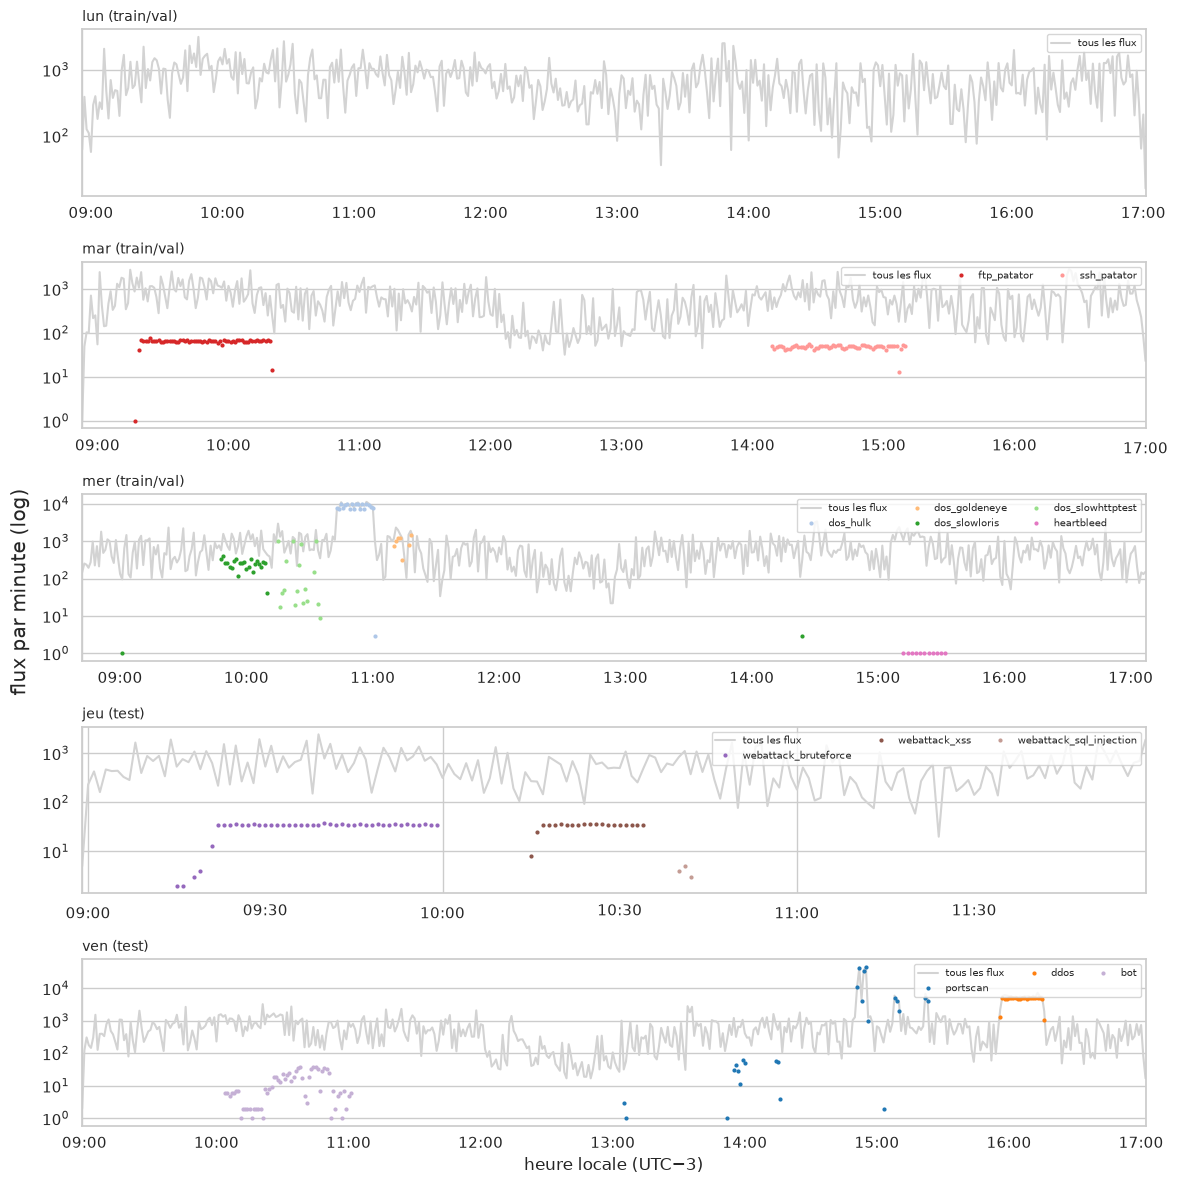

In [8]:
# Chronologie : nombre de flux d'attaque par minute, en heure locale
flows["minute"] = to_local_time(flows[TS]).dt.floor("min")
attacks = flows[flows[LABEL] != BENIGN]
attack_names = [name for name in classes.index if name != BENIGN]
colors = sns.color_palette("tab20", len(attack_names))

fig, axes = plt.subplots(len(DAYS), 1, figsize=(12, 12))
for ax, day in zip(axes, DAYS):
    # tout le trafic du jour, en gris
    all_per_minute = flows[flows["day"] == day].groupby("minute").size()
    all_per_minute.plot(ax=ax, color="lightgrey", label="tous les flux")

    # chaque attaque en points de couleur (une ligne relierait à tort des minutes sans attaque)
    for name, color in zip(attack_names, colors):
        this_attack = attacks[(attacks["day"] == day) & (attacks[LABEL] == name)]
        if len(this_attack) > 0:
            per_minute = this_attack.groupby("minute").size()
            per_minute.plot(ax=ax, color=color, label=name, style=".", ms=4)

    ax.set_yscale("log")
    ax.set_title(day + " (" + DAYS[day][1] + ")", loc="left", fontsize=10)
    ax.set_xlabel("")
    ax.legend(fontsize=7, loc="upper right", ncol=3)

axes[-1].set_xlabel("heure locale (UTC−3)")
fig.supylabel("flux par minute (log)")
fig.tight_layout()
fig.savefig(REPORTS / "01_chronologie_attaques.png", dpi=150)
plt.show()

In [9]:
# Heures de début et de fin de chaque attaque.
# Les quantiles 1 % et 99 % ignorent les quelques flux isolés loin de l'attaque.
window_tables = []
for day in DAYS:
    rows = []
    for name in attack_names:
        minutes = attacks.loc[(attacks["day"] == day) & (attacks[LABEL] == name), "minute"]
        if len(minutes) == 0:
            continue
        rows.append({
            "jour": day,
            "attaque": name,
            "début": minutes.min().strftime("%H:%M"),
            "1 %": minutes.quantile(0.01).strftime("%H:%M"),
            "99 %": minutes.quantile(0.99).strftime("%H:%M"),
            "fin": minutes.max().strftime("%H:%M"),
            "flux": len(minutes),
        })
    if len(rows) > 0:
        # dans un même jour, on range les attaques par heure de début
        window_tables.append(pd.DataFrame(rows).sort_values("1 %"))

pd.concat(window_tables).set_index(["jour", "attaque"])

début    1 %   99 %    fin    flux
jour attaque                                                    
mar  ftp_patator              09:17  09:19  10:19  10:20    4003
     ssh_patator              14:09  14:09  15:10  15:10    2959
mer  dos_slowloris            09:01  09:48  10:09  14:24    5674
     dos_slowhttptest         10:15  10:15  10:33  10:35    4866
     dos_hulk                 10:43  10:43  11:00  11:01  158988
     dos_goldeneye            11:10  11:10  11:18  11:18    6765
     heartbleed               15:12  15:12  15:31  15:32      11
jeu  webattack_bruteforce     09:15  09:21  09:59  09:59    1360
     webattack_xss            10:15  10:15  10:34  10:34     661
     webattack_sql_injection  10:40  10:40  10:42  10:42      12
ven  bot                      10:04  10:05  11:00  11:01     735
     portscan                 13:05  14:51  15:23  15:23  160106
     ddos                     15:56  15:56  16:16  16:16   95683

## 4. Aperçu du découpage 80/20 : où tombent les attaques ?

Deux lectures possibles de la règle « train = 80 % les plus anciens de lun, mar, mer » :
- **par jour** : les 80 % les plus anciens de chaque jour en train, les 20 % restants de chaque jour en val ;
- **global** : les 80 % les plus anciens des trois jours mis bout à bout (lun puis mar puis mer).

On compte les attaques de chaque classe dans train et val pour les deux lectures.

In [10]:
tv = flows[flows["day"].isin(train_days)].copy()

# Lecture « par jour » : une coupure (80e percentile du temps) pour chaque jour
tv["par jour"] = "val"
for day in train_days:
    in_day = tv["day"] == day
    cut = tv.loc[in_day, TS].quantile(0.8)
    tv.loc[in_day & (tv[TS] <= cut), "par jour"] = "train"
    print("Coupure par jour", day, ":", to_local_time(pd.Series([cut]))[0].strftime("%H:%M"))

# Lecture « globale » : une seule coupure sur les trois jours
global_cut = tv[TS].quantile(0.8)
tv["global"] = "val"
tv.loc[tv[TS] <= global_cut, "global"] = "train"
print("Coupure globale :", to_local_time(pd.Series([global_cut]))[0].strftime("%a %H:%M"))

by_day = pd.crosstab(tv[LABEL], tv["par jour"])
overall = pd.crosstab(tv[LABEL], tv["global"])
pd.concat({"par jour": by_day, "global": overall}, axis=1)

Coupure par jour lun : 15:15
Coupure par jour mar : 15:22
Coupure par jour mer : 14:34
Coupure globale : Wed 10:59


par jour          global        
par jour            train     val   train     val
label                                            
benign             762388  236401  777738  221051
dos_goldeneye        6765       0       0    6765
dos_hulk           158988       0  150407    8581
dos_slowhttptest     4866       0    4866       0
dos_slowloris        5674       0    5671       3
ftp_patator          4003       0    4003       0
heartbleed              0      11       0      11
ssh_patator          2959       0    2959       0

## 5. Caractéristiques constantes

Une caractéristique constante (minimum = maximum) sur train/val n'apporte rien au modèle. On décide sur lun/mar/mer uniquement (règle 7), puis on regarde ce qu'elle vaut en test.

In [11]:
constant_rows = []
for col in features:
    train_min = min(min_per_day[day][col] for day in train_days)
    train_max = max(max_per_day[day][col] for day in train_days)
    if train_min == train_max:
        test_min = min(min_per_day[day][col] for day in test_days)
        test_max = max(max_per_day[day][col] for day in test_days)
        constant_rows.append({"colonne": col, "valeur en train": train_min,
                              "test min": test_min, "test max": test_max})

print(len(constant_rows), "colonnes constantes sur train/val")
pd.DataFrame(constant_rows)

3 colonnes constantes sur train/val


,colonne,valeur en train,test min,test max
0,flag_urg,0.0,0.0,0.0
1,fwd_flag_urg,0.0,0.0,0.0
2,bwd_flag_urg,0.0,0.0,0.0


## 6. IP sources des attaques

Si chaque attaque vient de quelques IP fixes, un modèle qui verrait `src_addr` apprendrait l'IP et non le comportement : c'est pourquoi IP et ports source sont exclus des caractéristiques (règle 4).

In [12]:
ip_rows = []
for name in attack_names:
    ips = attacks.loc[attacks[LABEL] == name, "src_addr"]
    ip_counts = ips.value_counts()
    ip_rows.append({
        "attaque": name,
        "IP distinctes": len(ip_counts),
        "IP principale": ip_counts.index[0],
        "part de l'IP principale": round(ip_counts.iloc[0] / len(ips), 3),
    })
ip_table = pd.DataFrame(ip_rows).set_index("attaque").sort_values("IP distinctes")
ip_table

,IP distinctes,IP principale,part de l'IP principale
attaque,,,
portscan,1,172.16.0.1,1.000
dos_hulk,1,172.16.0.1,1.000
ddos,1,172.16.0.1,1.000
dos_goldeneye,1,172.16.0.1,1.000
dos_slowloris,1,172.16.0.1,1.000
dos_slowhttptest,1,172.16.0.1,1.000
ftp_patator,1,172.16.0.1,1.000
ssh_patator,1,172.16.0.1,1.000
webattack_bruteforce,1,172.16.0.1,1.000


In [13]:
# Ces IP envoient-elles aussi du trafic normal ? Si presque pas, l'IP seule « trahit » l'attaque.
benign = flows[flows[LABEL] == BENIGN]
leak_rows = []
for ip in ip_table["IP principale"].unique():
    n_benign = (benign["src_addr"] == ip).sum()
    n_attack = (attacks["src_addr"] == ip).sum()
    leak_rows.append({"IP": ip, "flux benign": n_benign, "flux attaque": n_attack,
                      "part benign": round(n_benign / (n_benign + n_attack), 4)})
pd.DataFrame(leak_rows).set_index("IP")

,flux benign,flux attaque,part benign
IP,,,
172.16.0.1,1383,441088,0.0031
192.168.10.15,115575,220,0.9981


## Observations

1. **Volume et qualité.** 1 837 498 flux, 83 colonnes dont 77 caractéristiques. 0 valeur manquante, 0 infinie, **0 doublon** quand `timestamp` est lu en float64 (les 11 « doublons » vus par `explore.py` venaient vraisemblablement du cast en float32, qui rend égaux des timestamps proches).
2. **Déséquilibre.** 441 823 attaques (24 % des flux), très inégales : de 160 106 (portscan) à 11 (heartbleed) et 12 (sql_injection). Métriques par classe obligatoires ; les classes à une dizaine de flux ne donneront pas de chiffre stable.
3. **Aucune attaque du test n'est vue en train/val** (rien en commun) : le RF ne pourra pas étiqueter correctement bot, ddos, portscan ni les attaques web ; c'est le rôle du détecteur d'anomalies.
4. **`timestamp`** : microsecondes Unix UTC, entiers exacts en float64, déjà triés dans chaque fichier. Journées de 9 h à 17 h heure locale (UTC−3), sauf jeudi limité à 9 h–12 h (après-midi d'infiltration retiré).
5. **Découpage 80/20 : la validation ne contient presque pas d'attaques.** Par jour, val = benign + 11 heartbleed ; en global, val = fin de mercredi (6 765 goldeneye, 8 581 hulk, 11 heartbleed, 3 slowloris) mais ni ftp, ni ssh, ni slowhttptest. → Décision (2 novembre) : découpage temporel **par classe**, voir notebook 02.
6. **Caractéristiques constantes** sur train/val : `flag_urg`, `fwd_flag_urg`, `bwd_flag_urg` (toujours 0, aussi en test) → retirées dans le notebook 02.
7. **Fuite par IP confirmée.** 12 des 13 classes d'attaque viennent d'une seule IP, `172.16.0.1` (la passerelle de l'attaquant), qui n'émet que 0,3 % de trafic benign (1 383 flux sur 442 471). Un modèle voyant `src_addr` « détecterait » l'IP. Seul bot vient de 5 postes internes (`192.168.10.x`) au trafic surtout benign. Règle 4 justifiée.
8. **Bords d'étiquetage.** Quelques flux isolés sont étiquetés hors de la fenêtre principale de l'attaque (ex. 4 flux dos_slowloris à 9 h 01 et 14 h 24, cœur 9 h 48–10 h 09). Le portscan commence par des flux épars dès 13 h 05 avant sa phase intense de 14 h 51 à 15 h 23.